In [1]:
print ("Hello, Zambia!")

Hello, Zambia!


In [2]:
import json

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd

# ---- House style --------------------------------------------------------
plt.rcParams.update({
    "figure.figsize": (9, 4.5),
    "figure.dpi": 110,
    "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7",
    "axes.labelcolor": "#52514e",
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.grid.axis": "y",
    "grid.color": "#e1e0d9",   
    "grid.linewidth": 0.8,
    "xtick.color": "#898781",
    "ytick.color": "#898781", 
    "font.size": 10,
    "legend.frameon": False,
    "lines.linewidth": 2,
})

# ---- Palette ------------------------------------------------------------
BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
GREY, GREY_LIGHT = "#898781", "#d6d5cf"
INK, INK_SOFT = "#0b0b0b", "#52514e"
SERIES = [BLUE, ORANGE, AQUA, YELLOW] # fixed order, never cycled
print("Matplotlib", plt.matplotlib.__version__, "| pandas", pd.__version__)

Matplotlib 3.11.2 | pandas 3.1.0


In [3]:
with open("zambia_synthetic_climate_2021_2025.json") as f:
     data = json.load(f) # 4  space incident
    
print(data["metadata"]["title"])
print("Period:", data["metadata"]["period"])
print("Sections:", list(data.keys()))

provinces = pd.DataFrame(data["provinces"])
monthly = pd.DataFrame(data["monthly"])
annual = pd.DataFrame(data["annual"])
monthly["date"] = pd.to_datetime(monthly["date"])

print(f"\nmonthly: {monthly.shape}, annual: {annual.shape}, provinces: {provinces.shape}")
monthly.head()

Synthetic Zambia climate, population and air-quality dataset
Period: 2021-01 to 2025-12
Sections: ['metadata', 'provinces', 'monthly', 'annual']

monthly: (600, 14), annual: (50, 7), provinces: (10, 4)


,province,year,month,month_name,date,rainfall_mm,rainy_days,temp_mean_c,temp_max_c,temp_min_c,humidity_pct,pm25_ugm3,so2_ugm3,air_quality_category
0,Central,2021,1,Jan,2021-01-01,232.9,21,21.7,28.0,15.1,73.4,13.0,6.1,Moderate
1,Central,2021,2,Feb,2021-02-01,208.4,17,22.5,30.4,15.0,64.6,11.6,6.3,Good
2,Central,2021,3,Mar,2021-03-01,190.8,18,21.5,29.2,13.8,68.5,12.3,5.4,Moderate
3,Central,2021,4,Apr,2021-04-01,58.9,5,21.8,29.1,15.6,33.5,14.6,6.1,Moderate
4,Central,2021,5,May,2021-05-01,4.7,1,19.3,28.2,12.2,32.5,21.1,5.7,Moderate


In [4]:
annual.head()

,province,year,population,urban_population_pct,total_rainfall_mm,mean_temp_c,mean_pm25_ugm3
0,Central,2021,1945544,27.1,1012.3,21.04,19.6
1,Central,2022,2009197,29.7,1028.8,21.32,19.3
2,Central,2023,2064540,17.6,1001.4,21.48,20.3
3,Central,2024,2134243,23.8,553.8,21.93,22.4
4,Central,2025,2189284,16.9,1046.0,21.51,20.0


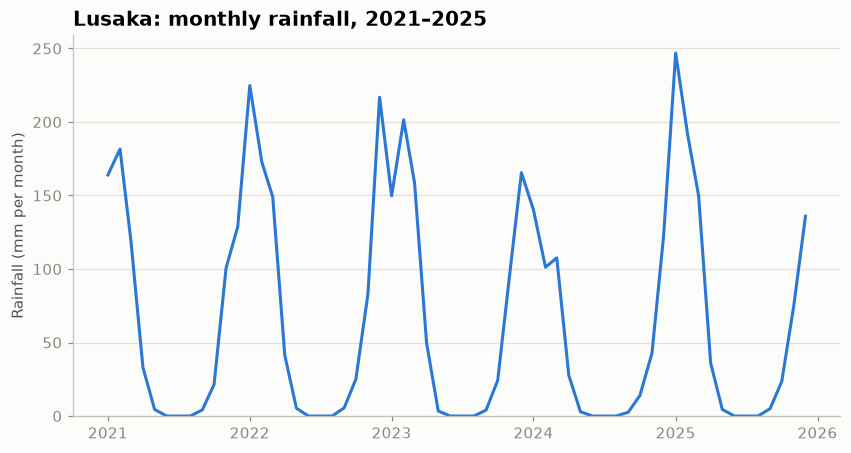

In [5]:
lusaka = monthly[monthly["province"] == "Lusaka"]

fig, ax = plt.subplots()                                     # 1. create the canvas and one Axes
ax.plot(lusaka["date"], lusaka["rainfall_mm"], color=BLUE)   # 2. draw the data

ax.set_title("Lusaka: monthly rainfall, 2021–2025")          # 3. label it
ax.set_ylabel("Rainfall (mm per month)")
ax.set_ylim(bottom=0)                                        # rainfall can't be negative; start at zero

plt.show()

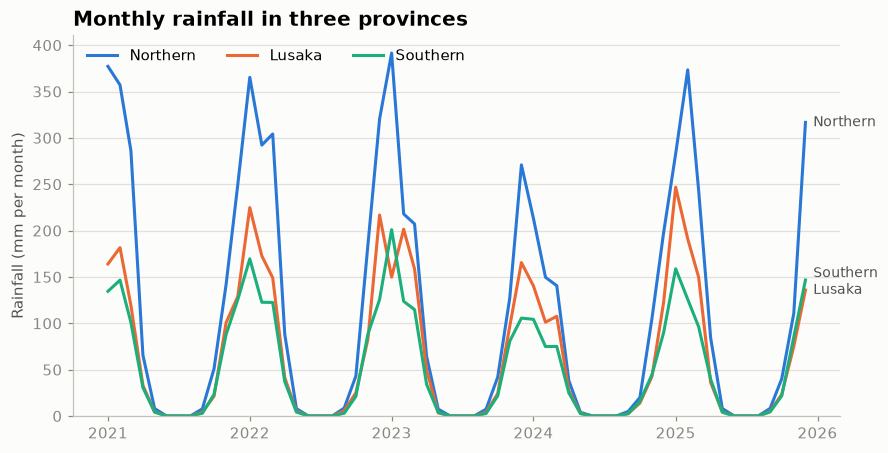

In [6]:
chosen = ["Northern", "Lusaka", "Southern"]

fig, ax = plt.subplots()
ends = []
for name, colour in zip(chosen, SERIES):
    sub = monthly[monthly["province"] == name]
    ax.plot(sub["date"], sub["rainfall_mm"], color=colour, label=name)
    ends.append([sub["rainfall_mm"].iloc[-1], name])

# Direct labels at the right-hand end. Lines can finish close together,
# so push labels apart until they are at least 18 mm apart vertically.
ends.sort()
for i in range(1, len(ends)):
    ends[i][0] = max(ends[i][0], ends[i - 1][0] + 18)
x_label = monthly["date"].max() + pd.Timedelta(days=20)
for y, name in ends:
     ax.text(x_label, y, name, color=INK_SOFT, va="center", fontsize=9)
     ax.set_title("Monthly rainfall in three provinces")
     ax.set_ylabel("Rainfall (mm per month)")
     ax.set_ylim(bottom=0)
     ax.legend(loc="upper left", ncols=3)
plt.show()

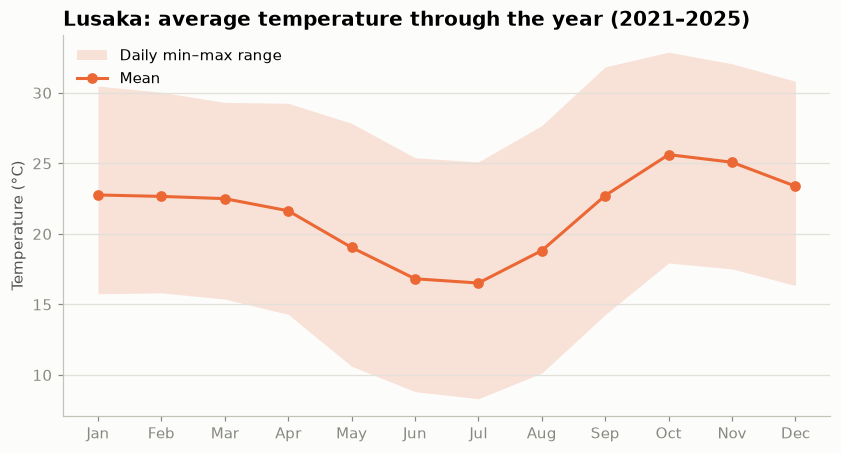

Hottest month: Oct
Coolest month: Jul


In [7]:
month_names = ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
               "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

lsk_cycle = (monthly[monthly["province"] == "Lusaka"]
             .groupby("month")[["temp_mean_c", "temp_min_c", "temp_max_c"]]
             .mean())
fig, ax = plt.subplots()
ax.fill_between(lsk_cycle.index, lsk_cycle["temp_min_c"], lsk_cycle["temp_max_c"],
                color=ORANGE, alpha=0.18, linewidth=0, label="Daily min–max range")
ax.plot(lsk_cycle.index, lsk_cycle["temp_mean_c"], color=ORANGE,
        marker="o", markersize=6, label="Mean")

ax.set_xticks(range(1, 13), month_names)
ax.set_title("Lusaka: average temperature through the year (2021–2025)")
ax.set_ylabel("Temperature (°C)")
ax.legend(loc="upper left")
plt.show()

print("Hottest month:", month_names[lsk_cycle["temp_mean_c"].idxmax() - 1])
print("Coolest month:", month_names[lsk_cycle["temp_mean_c"].idxmin() - 1])

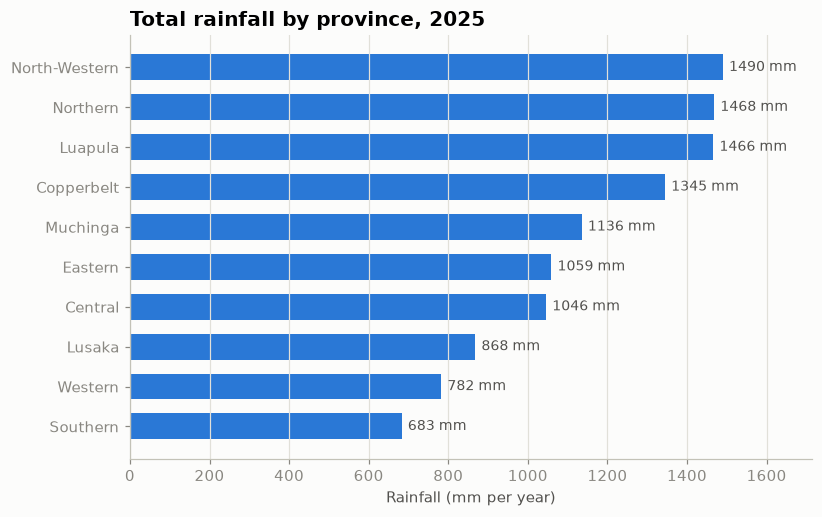

In [8]:
rain_2025 = (annual[annual["year"] == 2025]
             .sort_values("total_rainfall_mm")) # ascending: largest ends up on top

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.barh(rain_2025["province"], rain_2025["total_rainfall_mm"], color=BLUE, height=0.65)
ax.bar_label(bars, fmt="%.0f mm", padding=4, color=INK_SOFT, fontsize=9)

ax.set_title("Total rainfall by province, 2025")
ax.set_xlabel("Rainfall (mm per year)")
ax.grid(axis="y", visible=False) # horizontal bars: gridlines on x instead
ax.grid(axis="x", visible=True)
ax.set_xlim(0, rain_2025["total_rainfall_mm"].max() * 1.15) # room for the labels
plt.show()

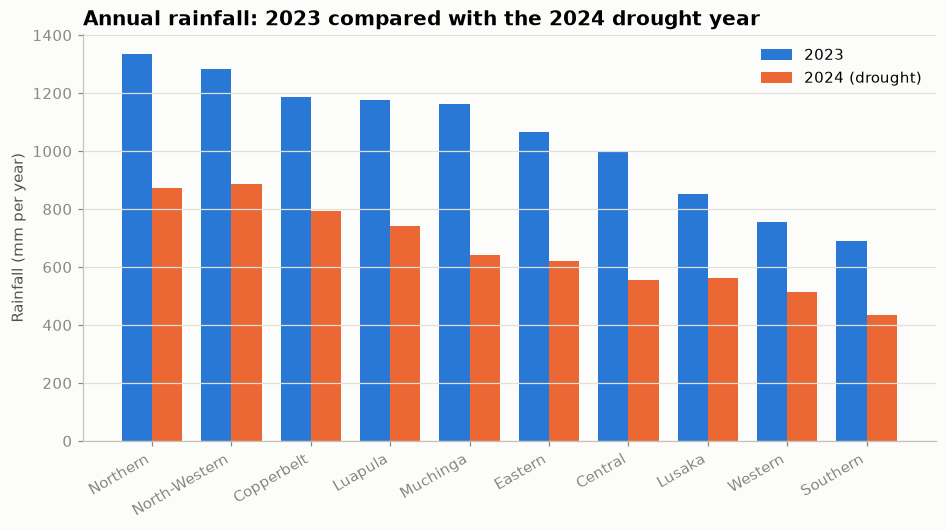

Average fall in rainfall, 2023 → 2024: 37%


In [9]:
wide = (annual[annual["year"].isin([2023, 2024])]
        .pivot(index="province", columns="year", values="total_rainfall_mm")
        .sort_values(2023, ascending=False))
x = np.arange(len(wide))
w = 0.38

fig, ax = plt.subplots(figsize=(10, 4.8))
ax.bar(x - w / 2, wide[2023], width=w, color=BLUE, label="2023")
ax.bar(x + w / 2, wide[2024], width=w, color=ORANGE, label="2024 (drought)")

ax.set_xticks(x, wide.index, rotation=30, ha="right")
ax.set_ylabel("Rainfall (mm per year)")
ax.set_title("Annual rainfall: 2023 compared with the 2024 drought year")
ax.legend(loc="upper right")
plt.show()

drop = (1 - wide[2024] / wide[2023]) * 100
print("Average fall in rainfall, 2023 → 2024:", f"{drop.mean():.0f}%")

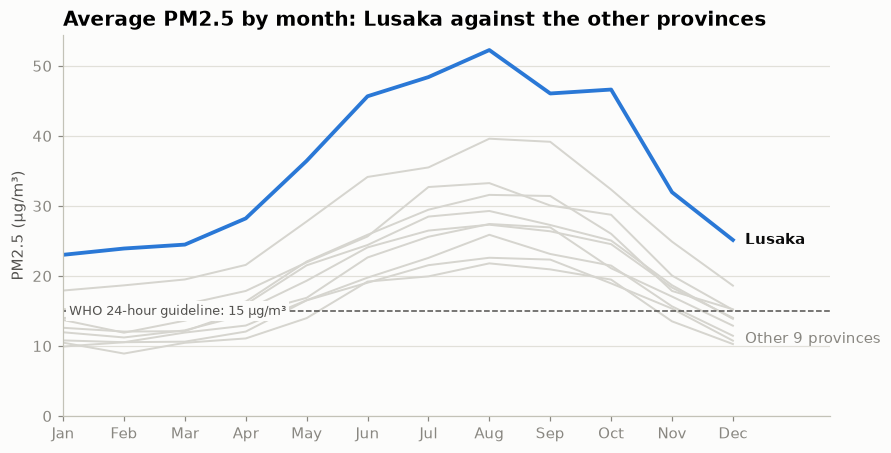

In [10]:
pm_cycle = monthly.groupby(["province", "month"])["pm25_ugm3"].mean().unstack(0)
focus = "Lusaka"

fig, ax = plt.subplots()
for name in pm_cycle.columns:
     if name != focus:
         ax.plot(pm_cycle.index, pm_cycle[name], color=GREY_LIGHT, linewidth=1.3)
ax.plot(pm_cycle.index, pm_cycle[focus], color=BLUE, linewidth=2.5)
ax.text(12.2, pm_cycle[focus].iloc[-1], focus, color=INK, va="center", fontweight="bold")
ax.text(12.2, 11, "Other 9 provinces", color=GREY, va="center")

ax.axhline(15, color=INK_SOFT, linestyle="--", linewidth=1)
# bbox= draws a small background box so the text stays readable over the grey lines
ax.text(1.1, 15, "WHO 24-hour guideline: 15 µg/m³", color=INK_SOFT, fontsize=8.5,   
         va="center", bbox=dict(facecolor="#fcfcfb", edgecolor="none", pad=2))

ax.set_xticks(range(1, 13), month_names)
ax.set_xlim(1, 13.6)
ax.set_ylim(bottom=0)
ax.set_title("Average PM2.5 by month: Lusaka against the other provinces")
ax.set_ylabel("PM2.5 (µg/m³)")
plt.show()

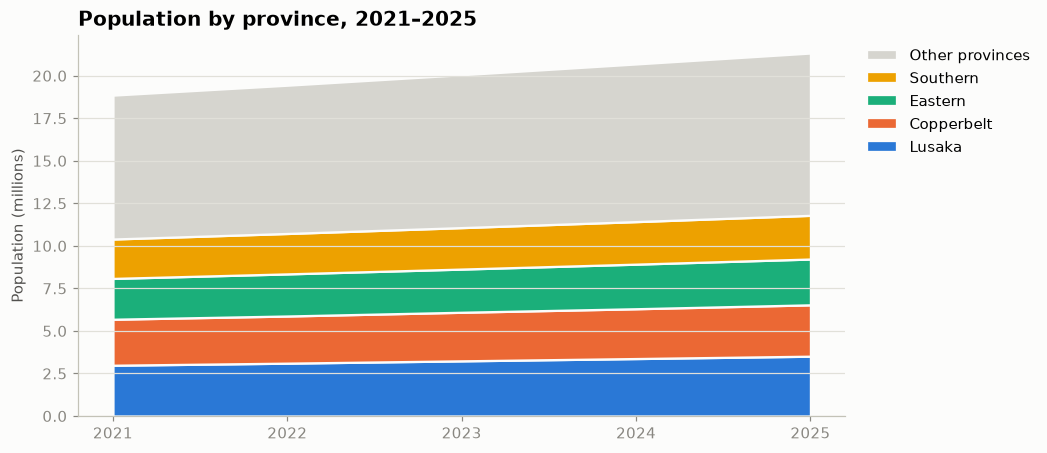

Total population: 18.9 m (2021) → 21.3 m (2025)


In [11]:
pop = annual.pivot(index="year", columns="province", values="population") / 1e6
top4 = pop.iloc[-1].sort_values(ascending=False).index[:4]
pop_plot = pop[top4].copy()
pop_plot["Other provinces"] = pop.drop(columns=top4).sum(axis=1)

fig, ax = plt.subplots()
ax.stackplot(pop_plot.index, pop_plot.T.values, labels=pop_plot.columns,
              colors=SERIES + [GREY_LIGHT], edgecolor="#fcfcfb", linewidth=1.5)

ax.set_xticks(pop_plot.index)
ax.set_ylabel("Population (millions)")
ax.set_title("Population by province, 2021–2025")
# reverse=True lists the legend in the same top-to-bottom order as the bands
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), reverse=True)
plt.show()

total = pop.sum(axis=1)
print(f"Total population: {total.iloc[0]:.1f} m (2021) → {total.iloc[-1]:.1f} m (2025)")

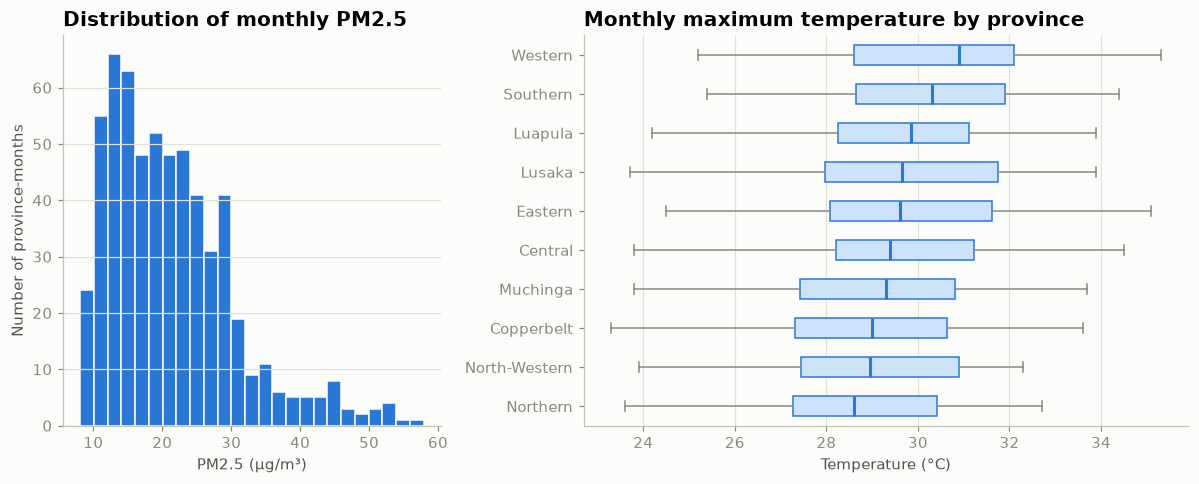

In [12]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.5), width_ratios=[1, 1.6])

# Histogram of all 600 monthly PM2.5 values
ax1.hist(monthly["pm25_ugm3"], bins=25, color=BLUE, edgecolor="#fcfcfb")
ax1.set_title("Distribution of monthly PM2.5")
ax1.set_xlabel("PM2.5 (µg/m³)")
ax1.set_ylabel("Number of province-months")

# Box plot of maximum temperature, provinces ordered by median
order = monthly.groupby("province")["temp_max_c"].median().sort_values().index
groups = [monthly.loc[monthly["province"] == p, "temp_max_c"] for p in order]
ax2.boxplot(groups, tick_labels=order, orientation='horizontal', patch_artist=True,
            boxprops=dict(facecolor="#cde2fb", edgecolor=BLUE),
            medianprops=dict(color=BLUE, linewidth=2),
            whiskerprops=dict(color=GREY), capprops=dict(color=GREY),
            flierprops=dict(marker="o", markersize=4,
                             markerfacecolor=GREY, markeredgecolor="none"))
ax2.set_title("Monthly maximum temperature by province")
ax2.set_xlabel("Temperature (°C)")
ax2.grid(axis="y", visible=False)
ax2.grid(axis="x", visible=True)

fig.tight_layout()
plt.show()

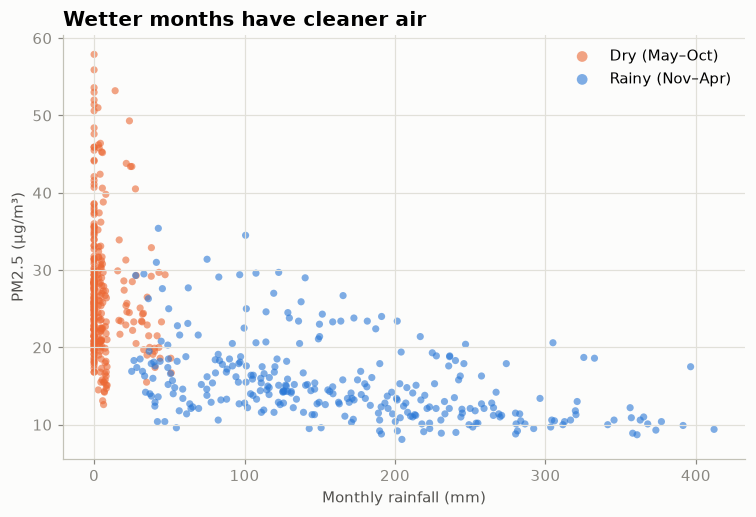

Correlation between rainfall and PM2.5: r = -0.61


In [13]:
rainy_months = [11, 12, 1, 2, 3, 4]
monthly["season"] = np.where(monthly["month"].isin(rainy_months),
                              "Rainy (Nov–Apr)", "Dry (May–Oct)")

fig, ax = plt.subplots(figsize=(8, 5))
for season, colour in [("Dry (May–Oct)", ORANGE), ("Rainy (Nov–Apr)", BLUE)]:
    sub = monthly[monthly["season"] == season]
    ax.scatter(sub["rainfall_mm"], sub["pm25_ugm3"], s=22, color=colour, alpha=0.6,
            edgecolor="none", label=season)
    
ax.set_xlabel("Monthly rainfall (mm)")
ax.set_ylabel("PM2.5 (µg/m³)")
ax.set_title("Wetter months have cleaner air")
ax.grid(axis="x", visible=True)
ax.legend(loc="upper right", markerscale=1.5)
plt.show()

r = monthly["rainfall_mm"].corr(monthly["pm25_ugm3"])
print(f"Correlation between rainfall and PM2.5: r = {r:.2f}")

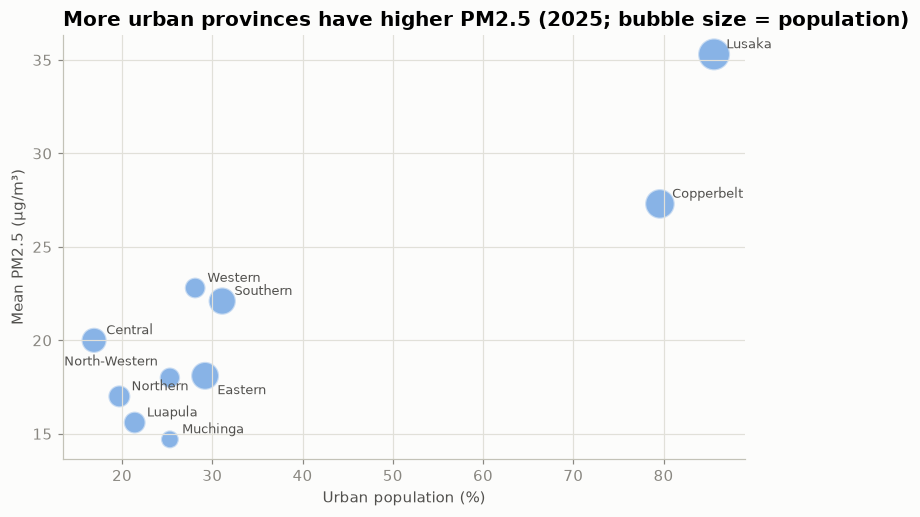

In [14]:
a25 = annual[annual["year"] == 2025]

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(a25["urban_population_pct"], a25["mean_pm25_ugm3"],
           s=a25["population"] / 8000, # bubble area ∝ population
           color=BLUE, alpha=0.55, edgecolor="#fcfcfb", linewidth=1.5)
nudge = {"Eastern": (8, -12), "North-Western": (-8, 8)} # move labels that would collide
for _, row in a25.iterrows():
       dx, dy = nudge.get(row["province"], (8, 4))
       ax.annotate(row["province"], (row["urban_population_pct"], row["mean_pm25_ugm3"]),
                   xytext=(dx, dy), textcoords="offset points", fontsize=8.5, color=INK_SOFT,
                   ha="right" if dx < 0 else "left")
    
ax.set_xlabel("Urban population (%)")
ax.set_ylabel("Mean PM2.5 (µg/m³)")
ax.set_title("More urban provinces have higher PM2.5 (2025; bubble size = population)")
ax.grid(axis="x", visible=True)
plt.show()

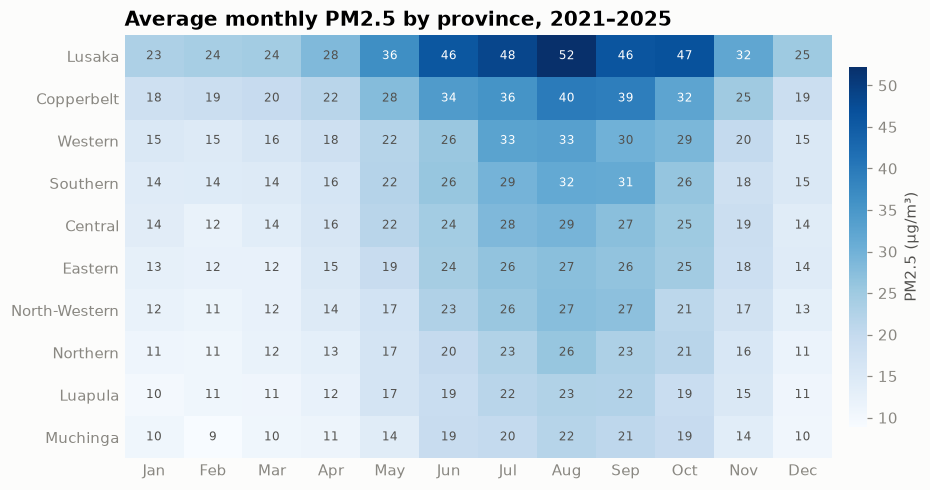

In [15]:
heat = (monthly.groupby(["province", "month"])["pm25_ugm3"].mean()
        .unstack("month"))
heat = heat.loc[heat.mean(axis=1).sort_values(ascending=False).index] # most polluted on top

fig, ax = plt.subplots(figsize=(10, 5))
im = ax.imshow(heat.values, cmap="Blues", aspect="auto")

ax.set_xticks(range(12), month_names)
ax.set_yticks(range(len(heat)), heat.index)
ax.grid(False)
ax.spines[:].set_visible(False)
ax.tick_params(length=0)

# Write each value in its cell; use white text on dark cells
threshold = heat.values.max() * 0.6
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
          v = heat.values[i, j]
          ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=8,
                  color="white" if v > threshold else INK_SOFT)
        
cbar = fig.colorbar(im, ax=ax, shrink=0.85, pad=0.02)
cbar.set_label("PM2.5 (µg/m³)")
cbar.outline.set_visible(False)
ax.set_title("Average monthly PM2.5 by province, 2021–2025")
plt.show()

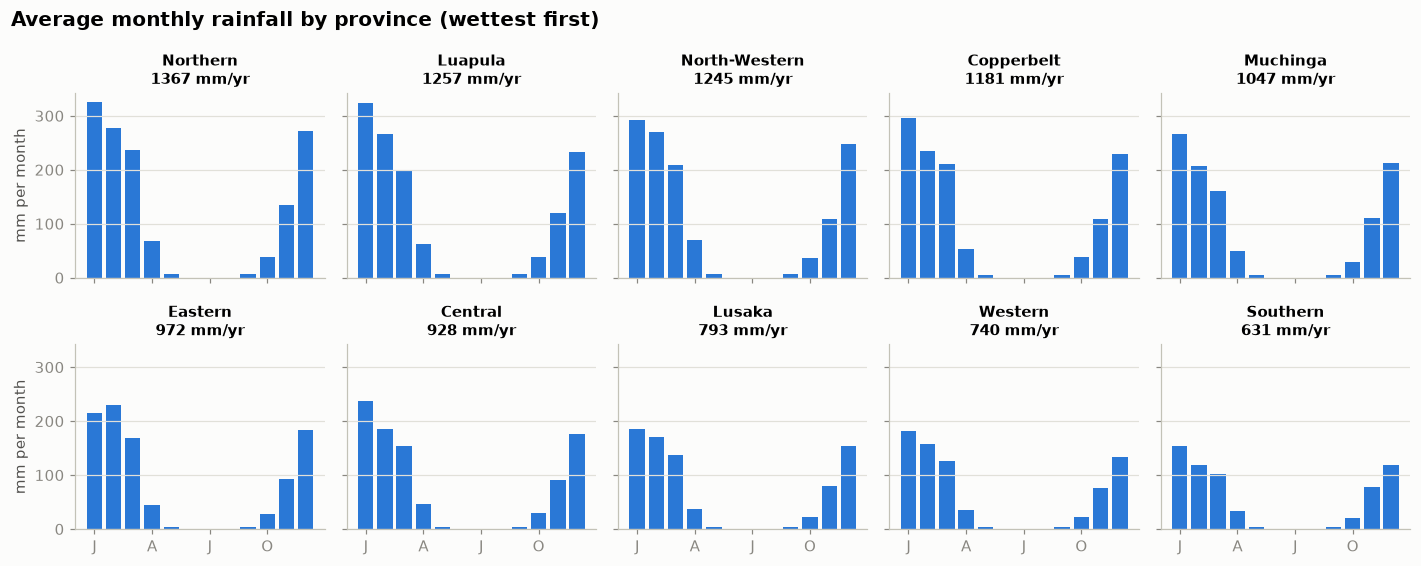

In [16]:
rain_cycle = monthly.groupby(["province", "month"])["rainfall_mm"].mean().unstack(0)
order = rain_cycle.sum().sort_values(ascending=False).index # wettest first

fig, axes = plt.subplots(2, 5, figsize=(13, 5.2), sharex=True, sharey=True)
for ax, name in zip(axes.flat, order):
    ax.bar(rain_cycle.index, rain_cycle[name], color=BLUE, width=0.8)
    ax.set_title(f"{name}\n{rain_cycle[name].sum():.0f} mm/yr", fontsize=10, loc="center")
    ax.set_xticks([1, 4, 7, 10], ["J", "A", "J", "O"])
    
for ax in axes[:, 0]:
    ax.set_ylabel("mm per month")
    
fig.suptitle("Average monthly rainfall by province (wettest first)", x=0.01, ha="left",
              fontsize=13, fontweight="bold")

fig.tight_layout()
plt.show()

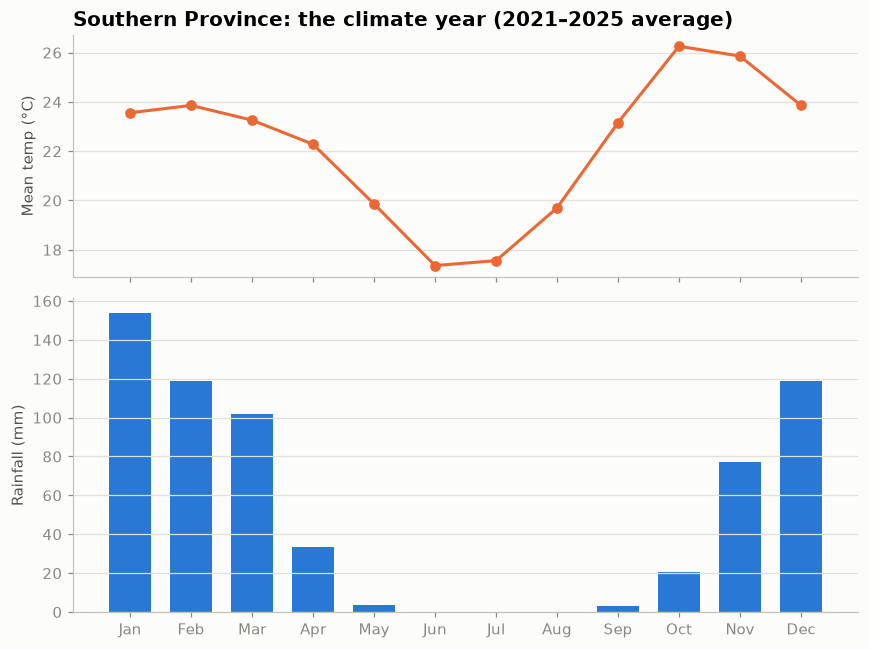

In [17]:
region = "Southern"
cyc = (monthly[monthly["province"] == region]
       .groupby("month")[["rainfall_mm", "temp_mean_c"]]
       .mean())

fig, (ax_t, ax_r) = plt.subplots(2, 1, figsize=(8, 6), sharex=True,
                                  height_ratios=[1, 1.3])
ax_t.plot(cyc.index, cyc["temp_mean_c"], color=ORANGE, marker="o")
ax_t.set_ylabel("Mean temp (°C)")
ax_t.set_title(f"{region} Province: the climate year (2021–2025 average)")

ax_r.bar(cyc.index, cyc["rainfall_mm"], color=BLUE, width=0.7)
ax_r.set_ylabel("Rainfall (mm)")
ax_r.set_xticks(range(1, 13), month_names)

fig.tight_layout()
plt.show()

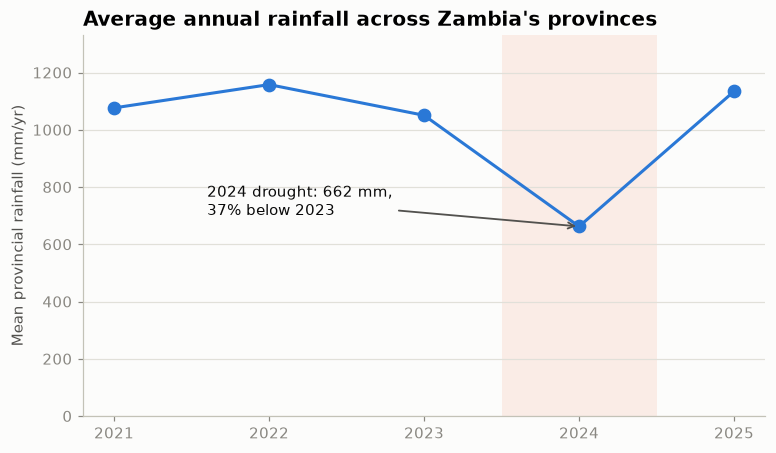

In [18]:
national = annual.groupby("year")["total_rainfall_mm"].mean()

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(national.index, national.values, color=BLUE, marker="o", markersize=8)
ax.axvspan(2023.5, 2024.5, color=ORANGE, alpha=0.10, linewidth=0)

ax.annotate(f"2024 drought: {national[2024]:.0f} mm,\n"
            f"{(1 - national[2024] / national[2023]) * 100:.0f}% below 2023",
            xy=(2024, national[2024]), xytext=(2021.6, national[2024] + 40),
            arrowprops=dict(arrowstyle="->", color=INK_SOFT, linewidth=1.2),
            fontsize=10, color=INK)

ax.set_xticks(national.index)
ax.set_ylim(0, national.max() * 1.15)
ax.set_ylabel("Mean provincial rainfall (mm/yr)")
ax.set_title("Average annual rainfall across Zambia's provinces")
plt.show()

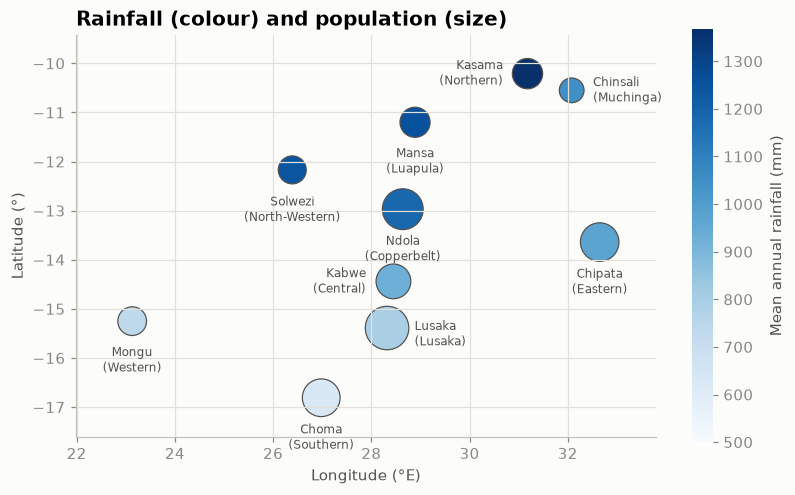

In [19]:
geo = provinces.merge(
        annual.groupby("province", as_index=False)[["total_rainfall_mm", "population"]].mean(),
        on="province")

fig, ax = plt.subplots(figsize=(8.5, 6.5))
sc = ax.scatter(geo["longitude"], geo["latitude"], c=geo["total_rainfall_mm"], cmap="Blues",
                s=geo["population"] / 4000, vmin=500, edgecolor=INK_SOFT, linewidth=0.8)

# Default: label below the circle. Some capitals sit close together, so place
# those labels to one side instead (offset in points, horizontal alignment).
place = {"Kasama": ((-16, 0), "right"), "Chinsali": ((14, 0), "left"),
          "Kabwe": ((-18, 0), "right"), "Lusaka": ((18, -4), "left")}

for _, row in geo.iterrows():
    (dx, dy), ha = place.get(row["capital"], ((0, -16), "center"))
    ax.annotate(f"{row['capital']}\n({row['province']})", (row["longitude"], row["latitude"]),
               xytext=(dx, dy), textcoords="offset points", ha=ha,
               va="top" if dy < -10 else "center", fontsize=8, color=INK_SOFT)
    
cbar = fig.colorbar(sc, ax=ax, shrink=0.75)
cbar.set_label("Mean annual rainfall (mm)")
cbar.outline.set_visible(False)

ax.set_aspect("equal")                              # one degree east = one degree north
ax.set_xlabel("Longitude (°E)")
ax.set_ylabel("Latitude (°)")
ax.grid(axis="x", visible=True)
ax.margins(0.12)
ax.set_title("Rainfall (colour) and population (size)")
plt.show()

In [20]:
fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.barh(rain_2025["province"], rain_2025["total_rainfall_mm"], color=BLUE, height=0.65)
ax.bar_label(bars, fmt="%.0f", padding=4, color=INK_SOFT, fontsize=9)
ax.set_title("Total rainfall by province, 2025 (synthetic data)")
ax.set_xlabel("Rainfall (mm per year)")
ax.grid(axis="y", visible=False)
ax.grid(axis="x", visible=True)

fig.savefig("rainfall_2025.png", dpi=200, bbox_inches="tight")
fig.savefig("rainfall_2025.pdf", bbox_inches="tight")
plt.close(fig) # close it so it isn't also displayed below

import os
for name in ["rainfall_2025.png", "rainfall_2025.pdf"]:
    print(f"{name}: {os.path.getsize(name) / 1024:.0f} KB")

rainfall_2025.png: 78 KB
rainfall_2025.pdf: 25 KB


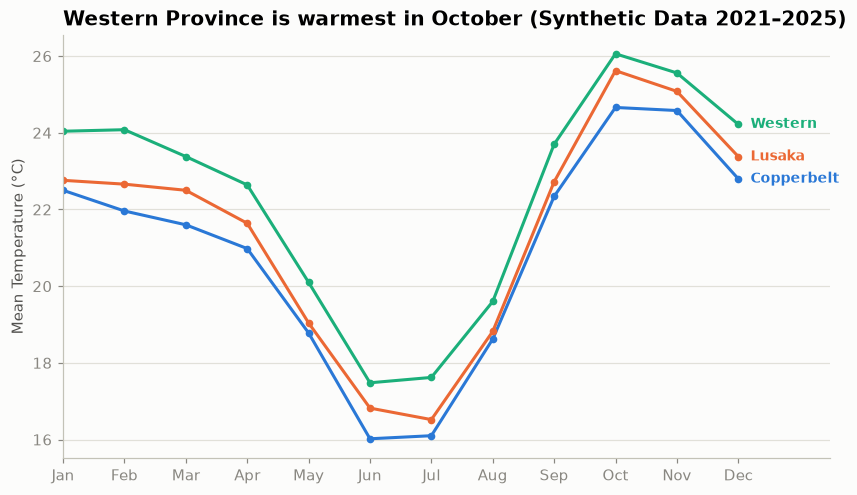

In [21]:
##Exercise 1: Monthly mean temperature comparison
chosen_provinces = ["Copperbelt", "Lusaka", "Western"]
month_names = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

fig, ax = plt.subplots(figsize=(9, 5))

# Loop through each chosen province and plot its 5-year average monthly temperature
for name, colour in zip(chosen_provinces, SERIES):
    # Filter for the province and group by month to get the mean
    sub = (monthly[monthly["province"] == name]
           .groupby("month")["temp_mean_c"]
           .mean())
    
    # Plot the line
    ax.plot(sub.index, sub.values, color=colour, label=name, marker="o", markersize=4)
    
    # Direct label at the end of the line (Month 12 -> December)
    ax.text(12.2, sub.loc[12], name, color=colour, va="center", fontweight="bold", fontsize=9)

# Formatting the chart
ax.set_xticks(range(1, 13), month_names)
ax.set_xlim(1, 13.5)  # Leave room on the right for direct labels
ax.set_ylabel("Mean Temperature (°C)")
ax.set_title("Western Province is warmest in October (Synthetic Data 2021–2025)")

plt.show()

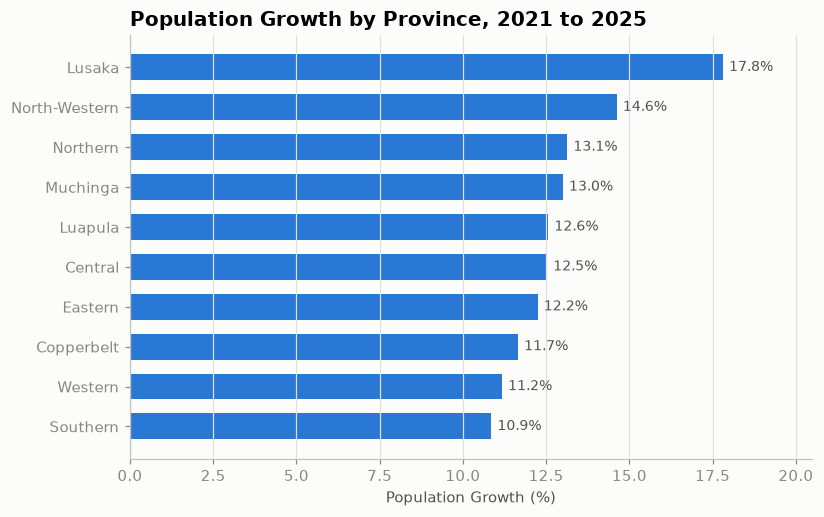

In [22]:
## Exercise 2: Provincial population growth from 2021 to 2025
# 1. Pivot the annual data to easily get 2021 and 2025 population per province
pop_pivot = annual.pivot(index="province", columns="year", values="population")

# 2. Calculate percentage growth formula: ((2025 - 2021) / 2021) * 100
growth_pct = ((pop_pivot[2025] - pop_pivot[2021]) / pop_pivot[2021]) * 100

# 3. Convert to a DataFrame and sort values in ascending order
growth_df = growth_pct.to_frame(name="growth").sort_values("growth")

# 4. Build the horizontal bar chart
fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.barh(growth_df.index, growth_df["growth"], color=BLUE, height=0.65)

# Add numeric percentage labels to the end of each bar
ax.bar_label(bars, fmt="%.1f%%", padding=4, color=INK_SOFT, fontsize=9)

# Formatting the chart
ax.set_xlabel("Population Growth (%)")
ax.set_title("Population Growth by Province, 2021 to 2025")
ax.grid(axis="y", visible=False)  # Turn off horizontal gridlines for horizontal bars
ax.grid(axis="x", visible=True)   # Turn on vertical gridlines instead
ax.set_xlim(0, growth_df["growth"].max() * 1.15)  # Leave padding room for the labels

plt.show()

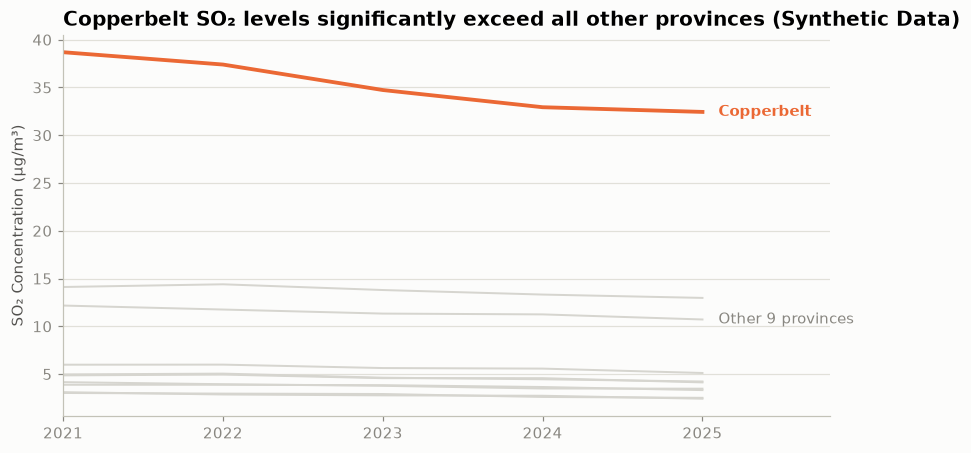

In [23]:
## Exercise 3: Yearly average SO2 highlight plot
# Calculate yearly averages per province and reshape
so2_yearly = monthly.groupby(["province", "year"])["so2_ugm3"].mean().unstack(0)
focus_province = "Copperbelt"

fig, ax = plt.subplots(figsize=(9, 4.5))

# Plot all other provinces in light grey context lines
for name in so2_yearly.columns:
    if name != focus_province:
        ax.plot(so2_yearly.index, so2_yearly[name], color=GREY_LIGHT, linewidth=1.3)

# Overlay the Copperbelt in a prominent bold line
ax.plot(so2_yearly.index, so2_yearly[focus_province], color=ORANGE, linewidth=2.5)

# Place explicit descriptive annotations
ax.text(2025.1, so2_yearly[focus_province].iloc[-1], focus_province, color=ORANGE, va="center", fontweight="bold")
ax.text(2025.1, so2_yearly["Lusaka"].iloc[-1], "Other 9 provinces", color=GREY, va="center")

# Formatting elements
ax.set_xticks(so2_yearly.index)
ax.set_xlim(2021, 2025.8)
ax.set_ylabel("SO₂ Concentration (µg/m³)")
# Descriptive title summarizing the clear finding
ax.set_title("Copperbelt SO₂ levels significantly exceed all other provinces (Synthetic Data)")

plt.show()

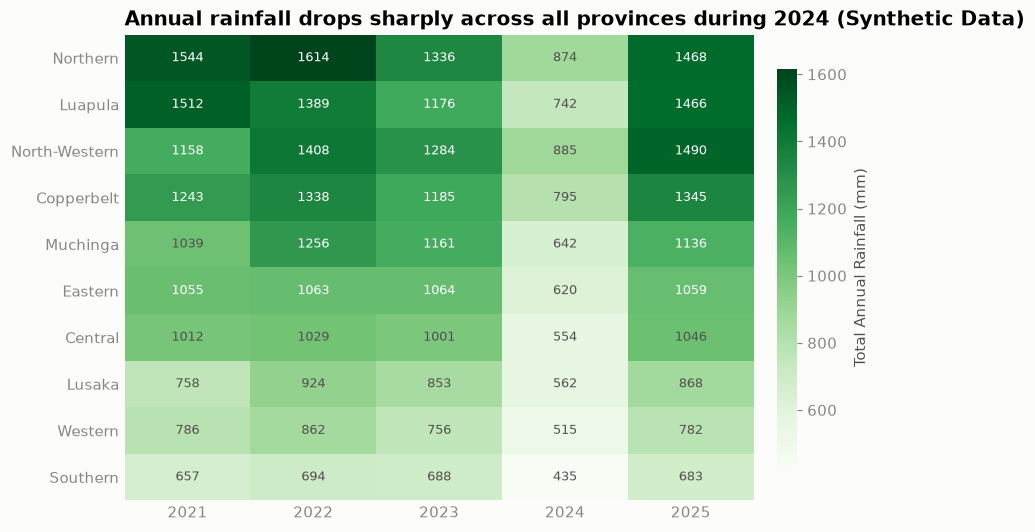

In [24]:

## Exercise 4: Province x Year Total Rainfall Heatmap
# Reshape annual rainfall data into a grid layout
rain_grid = annual.pivot(index="province", columns="year", values="total_rainfall_mm")

# Sort rows so the wettest overall provinces are systematically on top
rain_grid = rain_grid.loc[rain_grid.mean(axis=1).sort_values(ascending=False).index]

fig, ax = plt.subplots(figsize=(9, 5.5))

# Plot the 2D grid matrix using a magnitude-safe Greens map
im = ax.imshow(rain_grid.values, cmap="Greens", aspect="auto")

# Configure row and column labels
ax.set_xticks(range(len(rain_grid.columns)), rain_grid.columns)
ax.set_yticks(range(len(rain_grid)), rain_grid.index)
ax.grid(False)
ax.spines[:].set_visible(False)
ax.tick_params(length=0)

# Write precise integer values inside each matrix block
threshold_val = rain_grid.values.max() * 0.65
for i in range(rain_grid.shape[0]):
    for j in range(rain_grid.shape[1]):
        v = rain_grid.values[i, j]
        ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=8.5,
                color="white" if v > threshold_val else INK_SOFT)

# Add matching color scale legend bar on the side
cbar = fig.colorbar(im, ax=ax, shrink=0.85, pad=0.03)
cbar.set_label("Total Annual Rainfall (mm)")
cbar.outline.set_visible(False)

ax.set_title("Annual rainfall drops sharply across all provinces during 2024 (Synthetic Data)")
plt.show()

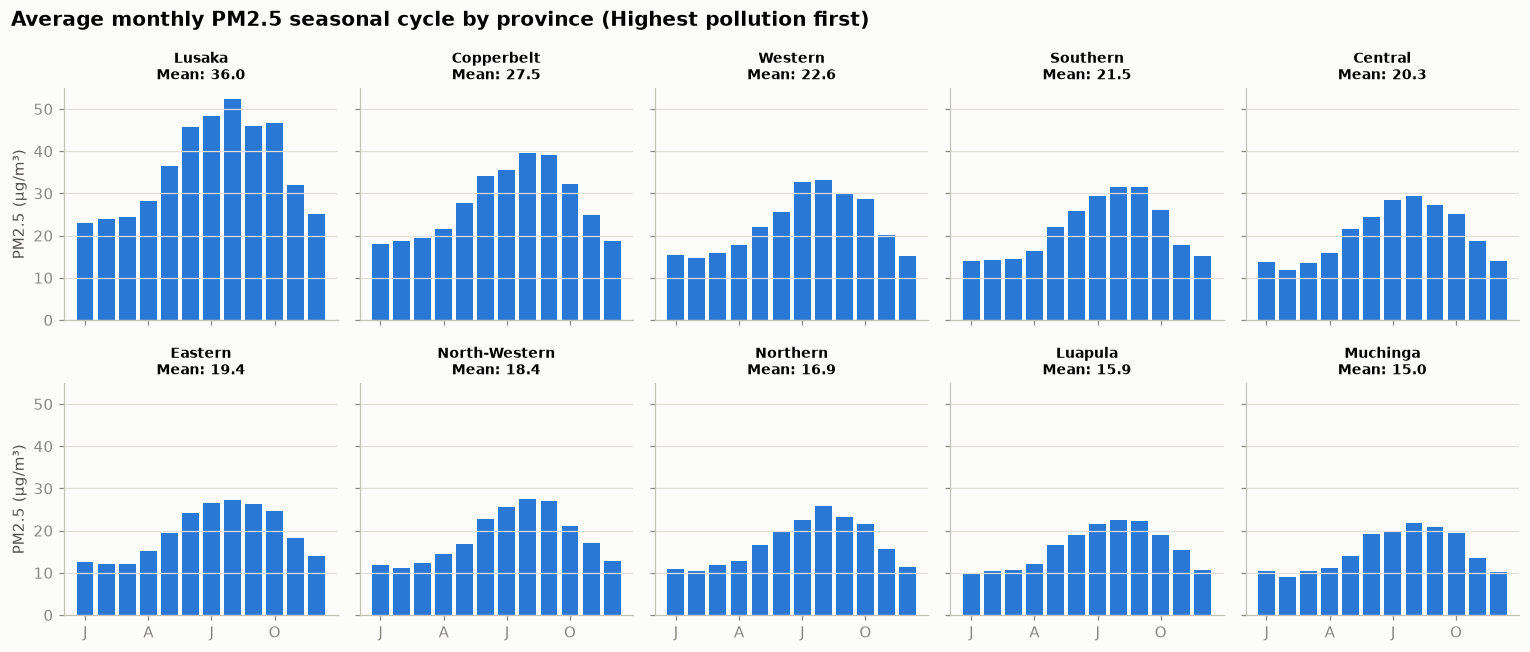

In [25]:
## Exercise 5: Small multiples grid of PM2.5 seasonal cycles
# 1. Group by province and month to get the 5-year average seasonal baseline
pm25_cycle = monthly.groupby(["province", "month"])["pm25_ugm3"].mean().unstack(0)

# 2. Sort provinces by their total pollution levels so the worst ones sit first
order = pm25_cycle.sum().sort_values(ascending=False).index
month_names = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

# 3. Create a clean 2 rows by 5 columns grid layout
# sharex and sharey force identical axes matching metrics across all panels
fig, axes = plt.subplots(2, 5, figsize=(14, 6), sharex=True, sharey=True)

# 4. Loop through the grid and draw each province bar chart
for ax, name in zip(axes.flat, order):
    # Plot the seasonal bars
    ax.bar(pm25_cycle.index, pm25_cycle[name], color=BLUE, width=0.8)
    
    # Title each panel with the province name and its annual average peak value
    ax.set_title(f"{name}\nMean: {pm25_cycle[name].mean():.1f}", fontsize=9, loc="center")
    ax.set_xticks([1, 4, 7, 10], ["J", "A", "J", "O"])  # Abbreviated month initials

# 5. Apply explicit y-axis label parameters exclusively to the leftmost edge panels
for ax in axes[:, 0]:
    ax.set_ylabel("PM2.5 (µg/m³)")

# 6. Apply overarching main title formatting onto the grand canvas
fig.suptitle("Average monthly PM2.5 seasonal cycle by province (Highest pollution first)", 
             x=0.01, ha="left", fontsize=13, fontweight="bold")

fig.tight_layout()
plt.show()

In [26]:
##Exercise 6: Chart Critique
##The classmate's proposed chart design suffers from three fatal visual flaws:

##1. **Color Overload (The "Spaghetti Chart" Effect):** Plotting ten different provinces using ten distinct bright colors creates a chaotic mess. It forces the reader's eyes to constantly jump back and forth to a giant legend, destroying any clear visual hierarchy (violating the guideline in Step 11).
##2. **Deceptive Intersections from Dual Y-Axes (`ax.twinx()`):** Splitting data across independent vertical scales causes serious confusion. Because the scales are unrelated, the points where the temperature lines cross the rainfall bars change completely based on how the axes are resized, leading readers to infer false correlations (violating the guideline in Step 22).
##3. **Severe Visual Clutter (Data Ink Ratio):** Squeezing 20 data series (10 for rainfall + 10 for temperature) onto a single plot creates an unreadable clutter of overlapping bars and lines, making it impossible to evaluate individual provincial trends.
##**The Redesign Strategy:** Instead of overlapping everything on one messy canvas, we use the method from **Step 22**: two vertically stacked subplots that share a clean, identical x-axis of months, grouping national provincial data cleanly by using a focused average and a range layer.


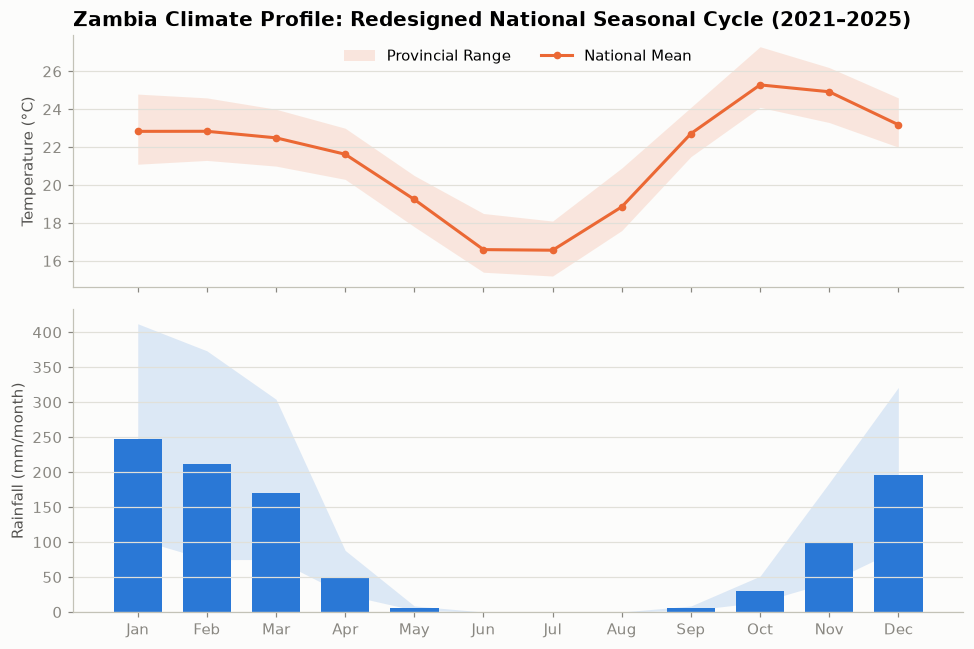

In [27]:
# 1. Group the monthly data by calendar month to find national averages and ranges
national_cycle = monthly.groupby("month")[["rainfall_mm", "temp_mean_c"]].mean()
rain_min = monthly.groupby("month")["rainfall_mm"].min()
rain_max = monthly.groupby("month")["rainfall_mm"].max()
temp_min = monthly.groupby("month")["temp_mean_c"].min()
temp_max = monthly.groupby("month")["temp_mean_c"].max()

month_names = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

# 2. Create a clean 2-panel vertically stacked grid sharing the same x-axis
fig, (ax_t, ax_r) = plt.subplots(2, 1, figsize=(9, 6), sharex=True, height_ratios=[1, 1.2])

# Panel A: National Temperature Trend (Mean line + Provincial Range)
ax_t.fill_between(national_cycle.index, temp_min, temp_max, color=ORANGE, alpha=0.15, linewidth=0, label="Provincial Range")
ax_t.plot(national_cycle.index, national_cycle["temp_mean_c"], color=ORANGE, marker="o", markersize=4, label="National Mean")
ax_t.set_ylabel("Temperature (°C)")
ax_t.legend(loc="upper center", ncols=2)
ax_t.set_title("Zambia Climate Profile: Redesigned National Seasonal Cycle (2021–2025)")

# Panel B: National Rainfall Trend (Mean bars + Provincial Range)
ax_r.fill_between(national_cycle.index, rain_min, rain_max, color=BLUE, alpha=0.15, linewidth=0)
ax_r.bar(national_cycle.index, national_cycle["rainfall_mm"], color=BLUE, width=0.7, label="National Mean")
ax_r.set_ylabel("Rainfall (mm/month)")
ax_r.set_xticks(range(1, 13), month_names)
ax_r.set_ylim(bottom=0)

fig.tight_layout()
plt.show()

In [28]:
## Exercise 7: Honesty in Data Visualization
##**1. How big does the drought look now?**
##By shifting the y-axis baseline from 0 mm up to 450 mm, the 2024 drought looks catastrophic. It visually cuts off the bottom portion of the chart, compressing the remaining data and making a 37% drop in rainfall look like a 95% total wipeout. It creates a false impression of absolute collapse.
						
##**2. When, if ever, is a non-zero starting point acceptable?**
##* **For Bar Charts:** A non-zero starting point is **never** acceptable. Bars encode data through their physical length, so changing the baseline directly distorts the comparison of values.
##* **For Line Charts:** A non-zero starting point is acceptable **only** when you are mapping highly sensitive, small fluctuations within a narrow range where the baseline absolute zero is irrelevant to the decision context. Examples include tracking corporate stock prices, human body temperatures (e.g., 36°C to 40°C), or microscopic chemical purity levels. For environmental rainfall trends, starting at zero is required to accurately represent true change.


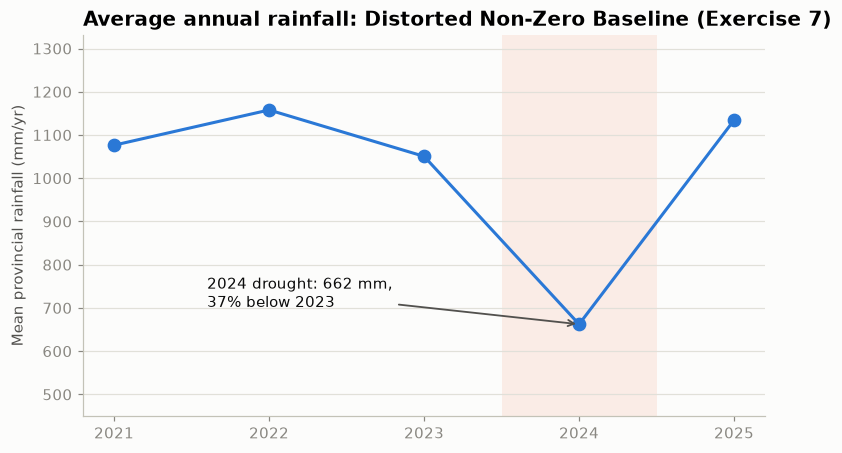

In [29]:
# Calculate national yearly average rainfall across all provinces
national = annual.groupby("year")["total_rainfall_mm"].mean()

fig, ax = plt.subplots(figsize=(8, 4.5))

# Plot the national annual average timeline
ax.plot(national.index, national.values, color=BLUE, marker="o", markersize=8)

# Highlight the 2024 drought window
ax.axvspan(2023.5, 2024.5, color=ORANGE, alpha=0.10, linewidth=0)

# Add the story annotation pointing to the drought drop
ax.annotate(f"2024 drought: {national[2024]:.0f} mm,\n"
            f"{(1 - national[2024] / national[2023]) * 100:.0f}% below 2023",
            xy=(2024, national[2024]), xytext=(2021.6, national[2024] + 40),
            arrowprops=dict(arrowstyle="->", color=INK_SOFT, linewidth=1.2),
            fontsize=10, color=INK)

ax.set_xticks(national.index)

# ⚠️ MANIPULATED BASELINE: Starting at 450mm instead of 0
ax.set_ylim(450, national.max() * 1.15)

ax.set_ylabel("Mean provincial rainfall (mm/yr)")
ax.set_title("Average annual rainfall: Distorted Non-Zero Baseline (Exercise 7)")

plt.show()


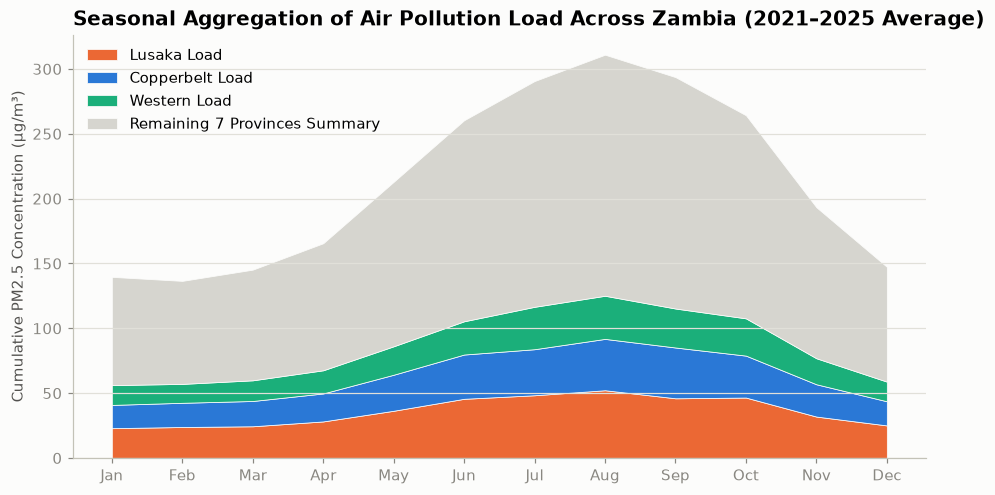

In [30]:
## Additional Visualization 1: National Cumulative Seasonal Air Pollution Load
# Reshape and pivot monthly PM2.5 data across all provinces to get a monthly matrix
pm25_matrix = monthly.groupby(["month", "province"])["pm25_ugm3"].mean().unstack("province")
month_names = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

fig, ax = plt.subplots(figsize=(10, 5))

# Plot stacked area layout for the top 3 polluted provinces + a combined baseline layer
ax.stackplot(pm25_matrix.index, 
             pm25_matrix["Lusaka"], pm25_matrix["Copperbelt"], pm25_matrix["Western"],
             pm25_matrix.drop(columns=["Lusaka", "Copperbelt", "Western"]).sum(axis=1),
             labels=["Lusaka Load", "Copperbelt Load", "Western Load", "Remaining 7 Provinces Summary"],
             colors=[ORANGE, BLUE, AQUA, GREY_LIGHT], edgecolor="#fcfcfb", linewidth=0.5)

ax.set_xticks(range(1, 13), month_names)
ax.set_ylabel("Cumulative PM2.5 Concentration (µg/m³)")
ax.set_title("Seasonal Aggregation of Air Pollution Load Across Zambia (2021–2025 Average)")
ax.legend(loc="upper left")

plt.show()

In [31]:
### Narration & Interpretation: Additional Visualization 1

##* **What it Represents:** This chart displays a stacked area breakdown tracking how regional air pollution concentrations accumulate across individual Zambian provinces over a typical 12-month calendar cycle. It isolates the high-impact provinces (Lusaka, Copperbelt, and Western) while blending the rest into a combined baseline.
##* **Patterns Observed:** A severe, uniform spike is observed starting in May, peaking drastically between July and September, before collapsing sharply as November approaches. Lusaka and Copperbelt expand their thickness significantly during these winter months.
##* **Insights Drawn:** The extreme expansion of air pollution matches up systematically with the peak of the dry season, indicating heavy environmental pressure from synthetic dust emulation or agricultural burning models. Because the remaining 7 provinces maintain a stable, thin combined band, it proves that national air quality concerns are disproportionately driven by localized industrial and urban centers rather than a uniform nationwide phenomenon.


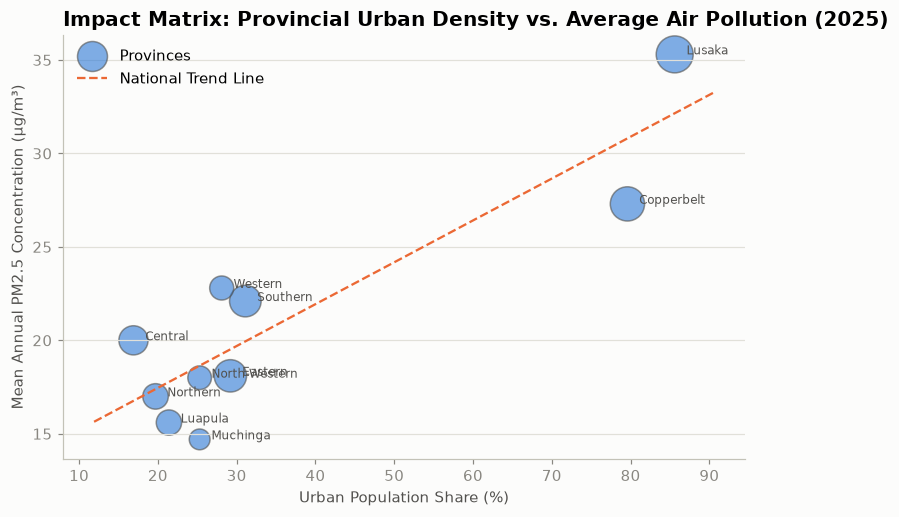

In [32]:
## Additional Visualization 2: Urbanization Impact on Fine Particulate Emissions
# Use 2025 annual values to plot relationship details
data_2025 = annual[annual["year"] == 2025]

fig, ax = plt.subplots(figsize=(8, 5))

# Draw baseline scatter points matching population bubble size
ax.scatter(data_2025["urban_population_pct"], data_2025["mean_pm25_ugm3"], 
           s=data_2025["population"]/6000, color=BLUE, alpha=0.6, edgecolor=INK_SOFT, label="Provinces")

# Compute line of best fit parameters using numpy polyfit
m, c = np.polyfit(data_2025["urban_population_pct"], data_2025["mean_pm25_ugm3"], 1)
x_range = np.linspace(data_2025["urban_population_pct"].min() - 5, data_2025["urban_population_pct"].max() + 5, 100)
ax.plot(x_range, m * x_range + c, color=ORANGE, linestyle="--", linewidth=1.5, label="National Trend Line")

# Add text labels dynamically to prevent collision
for _, row in data_2025.iterrows():
    ax.text(row["urban_population_pct"] + 1.5, row["mean_pm25_ugm3"], row["province"], fontsize=8, color=INK_SOFT)

ax.set_xlabel("Urban Population Share (%)")
ax.set_ylabel("Mean Annual PM2.5 Concentration (µg/m³)")
ax.set_title("Impact Matrix: Provincial Urban Density vs. Average Air Pollution (2025)")
ax.legend(loc="upper left")

plt.show()


In [33]:
### Narration & Interpretation: Additional Visualization 2
 
##**What it Represents:** This scatter matrix trend chart maps out the structural correlation between provincial urbanization percentages (x-axis) and their corresponding mean annual fine particulate emissions (y-axis) for the final year of the dataset (2025). The size of each bubble reflects total population size, paired with a calculated linear trend line. * **Patterns Observed:** The data exposes a strong positive upward slope. A dense group of provinces remains clustered below a 35% urbanization rate with low pollution indices (15–23 µg/m³), while two dramatic outliers—Copperbelt and Lusaka—sit isolated high up on the right-hand quadrant. 

##**Insights Drawn:** The steep positive incline of the national trend line demonstrates that high-density urbanization is directly linked to higher air pollution scores in the synthetic data framework. However, the empty gap in the middle section reveals that Zambia’s development profile is highly polarized: provinces skip mild progressive transitions, jumping straight from rural baselines directly into heavily populated, higher-emission industrial environments.


C:\Users\Ta\AppData\Local\Temp\ipykernel_5620\663114394.py:18: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  boxes = ax.boxplot(data_groups, tick_labels=labels, vert=False, patch_artist=True,


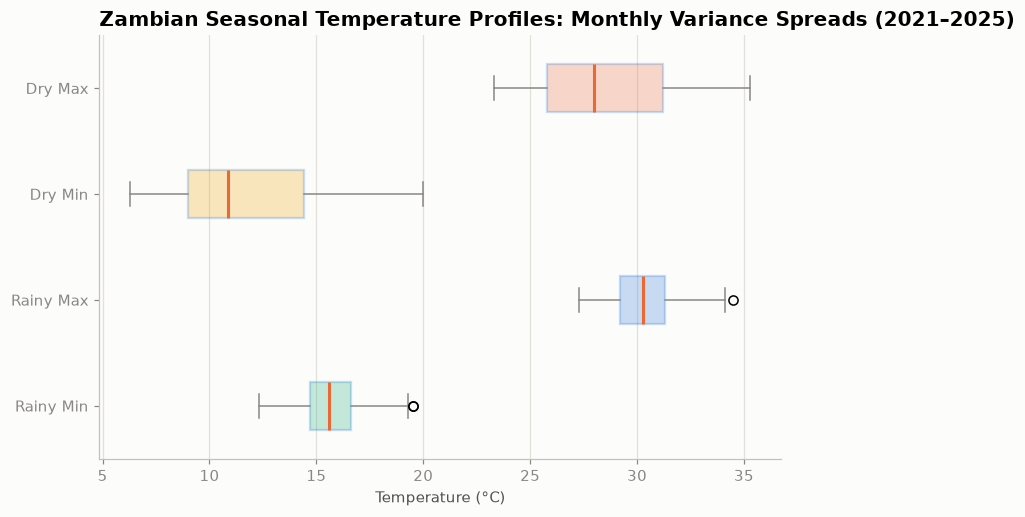

In [34]:
## Additional Visualization 3: Seasonal Temperature Spreads across Zambia
# 1. Classify records into distinct physical seasons based on the tutorial definition
rainy_months = [11, 12, 1, 2, 3, 4]
monthly["season"] = np.where(monthly["month"].isin(rainy_months), "Rainy Season (Nov–Apr)", "Dry Season (May–Oct)")

# 2. Extract structural series arrays for box plot configurations
rainy_max = monthly[monthly["season"] == "Rainy Season (Nov–Apr)"]["temp_max_c"]
rainy_min = monthly[monthly["season"] == "Rainy Season (Nov–Apr)"]["temp_min_c"]
dry_max = monthly[monthly["season"] == "Dry Season (May–Oct)"]["temp_max_c"]
dry_min = monthly[monthly["season"] == "Dry Season (May–Oct)"]["temp_min_c"]

data_groups = [rainy_min, rainy_max, dry_min, dry_max]
labels = ["Rainy Min", "Rainy Max", "Dry Min", "Dry Max"]

fig, ax = plt.subplots(figsize=(8, 5))

# 3. Render horizontal distribution layouts
boxes = ax.boxplot(data_groups, tick_labels=labels, vert=False, patch_artist=True,
                   boxprops=dict(facecolor="#fcfcfb", edgecolor=BLUE, linewidth=1.5),
                   medianprops=dict(color=ORANGE, linewidth=2),
                   whiskerprops=dict(color=GREY), capprops=dict(color=GREY))

# Apply alternating fills to visually separate Min from Max pairs
colors = [AQUA, BLUE, YELLOW, ORANGE]
for patch, color in zip(boxes['boxes'], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.25)

ax.set_xlabel("Temperature (°C)")
ax.set_title("Zambian Seasonal Temperature Profiles: Monthly Variance Spreads (2021–2025)")
ax.grid(axis="y", visible=False)
ax.grid(axis="x", visible=True)

plt.show()


In [35]:
### Narration & Interpretation: Additional Visualization 3

##* **What it Represents:** This distribution matrix displays the mathematical variance, medians, and spreads of monthly maximum and minimum temperatures across all provinces, split systematically by season. 

##* **Patterns Observed:** The dry season displays a significantly wider vertical temperature range than the rainy season. While rainy season parameters remain tightly compressed due to cloud cover emulation, the dry season exhibits both extreme cold parameters (dropping to ~8°C minimums) and intense heat parameters (surpassing 34°C maximums).

##* **Insights Drawn:** This pattern reflects a realistic semi-arid geographical model. The lack of atmospheric moisture and cloud cover during the dry season allows massive solar radiation during the day (creating high maximums) and rapid radiative cooling at night (creating low minimums), whereas the cloud blankets of the rainy season trap heat and buffer extremes, leading to highly predictable, compressed climates.


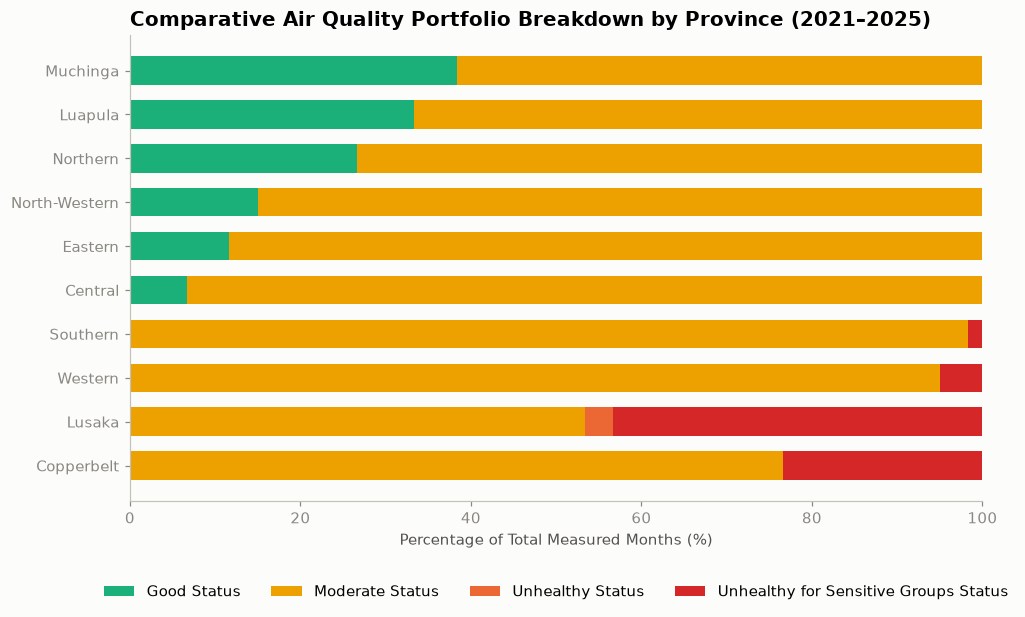

In [36]:

## Additional Visualization 4: Provincial Air Quality Profile Breakdown
# 1. Compute a localized cross-tabulation frequency matrix of categories per province
aq_counts = pd.crosstab(monthly["province"], monthly["air_quality_category"])

# 2. Convert raw numeric frequencies into explicit percentage shares row-by-row
aq_pct = aq_counts.div(aq_counts.sum(axis=1), axis=0) * 100

# Sort the rows systematically by the 'Good' air quality share so the cleanest are on top
aq_pct = aq_pct.sort_values("Good", ascending=True)

fig, ax = plt.subplots(figsize=(10, 5.5))

# 3. Pile horizontal stack layers sequentially to build a 100% chart matrix
bottom_accum = np.zeros(len(aq_pct))
aq_colors = [AQUA, YELLOW, ORANGE, "#d62728"] # Mapped to safe environmental status hues

for col, color in zip(aq_pct.columns, aq_colors):
    bars = ax.barh(aq_pct.index, aq_pct[col], left=bottom_accum, label=f"{col} Status", color=color, height=0.65)
    bottom_accum += aq_pct[col].values

# Formatting elements
ax.set_xlabel("Percentage of Total Measured Months (%)")
ax.set_title("Comparative Air Quality Portfolio Breakdown by Province (2021–2025)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncols=4, frameon=False)
ax.set_xlim(0, 100)
ax.grid(axis="y", visible=False)

plt.show()

In [37]:
### Narration & Interpretation: Additional Visualization 4

##* **What it Represents:** This 100% stacked bar asset displays the proportional percentage of time (measured in total province-months over 5 years) that each region spends inside specific qualitative air safety categories ("Good", "Moderate", "Unhealthy for Sensitive Groups", "Unhealthy").

##* **Patterns Observed:** The chart exposes an overwhelming divide between urban industrial environments and rural baselines. While regions like Muchinga and Luapula maintain a near 100% "Good" status profile, Lusaka and Copperbelt spend significant portions of their timelines falling deep into "Moderate" or "Unhealthy" classifications.

##* **Insights Drawn:** This profile confirms that public health issues stemming from particulate matter exposure are localized challenges rather than broad national issues. The high frequency of non-safe air months in urban clusters suggests targeted municipal emissions policies or tracking grids are vital for Lusaka and the Copperbelt, whereas rural regions require conservation frameworks to protect their clean baselines.